```{index} single: solver; Ipopt
```
```{index} single: application; portfolio
```
```{index} single: application; investment
```
```{index} single: solver; MOSEK
```

# 6.3 Markowitz portfolio optimization revisited

## Preamble: Install Pyomo and a solver

This cell selects and verifies a global SOLVER for the notebook.

If run on Google Colab, the cell installs Pyomo and ipopt, then sets SOLVER to use the ipopt solver. If run elsewhere, it assumes Pyomo and the Mosek solver
have been previously installed and sets SOLVER to use the Mosek solver via the Pyomo SolverFactory. It then verifies that SOLVER is available.

See [Solvers used in this book](../appendix/installing-pyomo-and-solvers.ipynb) for installation, licensing and the differences between solver interfaces.


In [1]:
import sys, os

if 'google.colab' in sys.modules:
    %pip install idaes-pse --pre >/dev/null 2>/dev/null
    !idaes get-extensions --to ./bin 
    os.environ['PATH'] += ':bin'
    solver = "ipopt"
else:
    solver = "mosek_direct"

import pyomo.environ as pyo 
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

In [2]:
from IPython.display import Markdown, HTML
import numpy as np
import matplotlib.pyplot as plt

## Problem description and model formulation

Consider again the [Markowitz portfolio optimization](../05/03-markowitz-portfolio.ipynb) we presented earlier in Chapter 5. Recall that the matrix $\Sigma$ describes the covariance among the uncertain return rates $r_i$, $i=1,\dots, n$. Since $\Sigma$ is positive semidefinite by definition, it allows for a Cholesky factorization, namely $\Sigma = B B^\top$. We can then rewrite the variance constraint $x^\top \Sigma x \leq \gamma$ as $\|B^\top x \|_2 \leq \sqrt{\gamma}$ and thus as $(\sqrt{\gamma}, B^\top x) \in \mathcal{L}^{n+1}$ using the Lorentz cone. In this way, we realize that the original portfolio problem we formulated [earlier](../05/03-markowitz-portfolio.ipynb) is in fact a conic quadratic optimization problem, which can thus be solved faster and more reliably. The optimal solution of that problem was the one with the maximum expected return while allowing for a specific level $\gamma$ of risk. 

However, an investor could aim for a different trade-off between return and risk and formulate a slightly different optimization problem, namely

$$
\begin{align*}
    \max \quad  &  R \tilde{x} + \mu^\top x - \alpha x^\top \Sigma x \\
    \text{s.t.}\quad
    & \sum_{i=1}^n x_i + \tilde{x}  = C  \\
    & \tilde x \geq 0\\
    & x_i \geq 0 & \forall \, i=1,\dots,n. 
\end{align*}
$$

where $\alpha \geq 0$ is a *risk aversion* parameter that describes the relative importance of return vs. risk for the investor: a larger value gives a greater penalty to variance. The risk, quantified by the variance of the investment return $x^\top \Sigma x = x^\top B B^\top x = \|B^\top x\|_2^2$, appears now in the objective function as a penalty term. Note that even in this new formulation we have a conic problem since we can rewrite it as

$$
\begin{align*}
    \max \quad  &  R \tilde{x} + \mu^\top x - \alpha s \\
    \text{s.t.}\quad
    & \sum_{i=1}^n x_i + \tilde{x}  = C  \\
    & \| B^\top x\|^2_2 \leq s\\
    & \tilde x \geq 0 \\
    & s \geq 0\\
    & x_i \geq 0 & \forall \, i=1,\dots,n. 
\end{align*}
$$

Varying $\alpha$ gives portfolios with different return–risk trade-offs. Plotting their expected returns against their variances gives the **efficient frontier**. The plot below instead shows the optimal penalized objective value as a function of $\alpha$.

In [3]:
# Specify the initial capital, the risk aversion, and the guaranteed return rate.
C = 1
alpha = 0.1
R = 1.05

# Specify the number of assets, their expected return, and their covariance matrix.
n = 3
mu = np.array([1.25, 1.15, 1.35])
Sigma = np.array([[1.5, 0.5, 2], [0.5, 2, 0], [2, 0, 5]])

# Check that Sigma is positive semidefinite
assert np.all(np.linalg.eigvals(Sigma) >= 0)

# When changing the covariance matrix Sigma, ensure you input a positive semidefinite one.
# The easiest way to generate a random covariance matrix is first generating a random
# m x m matrix A and then taking the matrix A^T A (which is always positive semidefinite)
# m = 3
# A = np.random.rand(m, m)
# Sigma = A.T @ A
#
# Moreover, in practice such a matrix A, called factor, can be low-rank,
# see https://docs.mosek.com/modeling-cookbook/qcqo.html#example-factor-model.
# This would provide better numerical properties for the proper conic formulation
#   y=Ax, |y|^2 <= s,
# corresponding to the mathematical formulation above.


def markowitz_revisited(alpha, mu, Sigma):
    model = pyo.ConcreteModel("Markowitz portfolio optimization revisited")

    model.xtilde = pyo.Var(domain=pyo.NonNegativeReals)
    model.x = pyo.Var(range(n), domain=pyo.NonNegativeReals)
    model.s = pyo.Var(domain=pyo.NonNegativeReals)

    @model.Objective(sense=pyo.maximize)
    def objective(m):
        return mu @ m.x + R * m.xtilde - alpha * m.s

    @model.Constraint()
    def bounded_variance(m):
        return (m.x @ (Sigma @ m.x)) <= m.s

    @model.Constraint()
    def total_assets(m):
        return sum(m.x[i] for i in range(n)) + m.xtilde == C

    return model


model = markowitz_revisited(alpha, mu, Sigma)
result = SOLVER.solve(model)
display(
    Markdown(
        f"**Solver status:** *{result.solver.status}, {result.solver.termination_condition}*"
    )
)
display(
    Markdown(
        f"**Solution:** $\\tilde x = {model.xtilde.value:.3f}$, $x_1 = {model.x[0].value:.3f}$,  $x_2 = {model.x[1].value:.3f}$,  $x_3 = {model.x[2].value:.3f}$"
    )
)
display(Markdown(f"**Maximizes objective value to:** ${model.objective():.2f}$"))

**Solver status:** *ok, optimal*

**Solution:** $\tilde x = 0.283$, $x_1 = 0.478$,  $x_2 = 0.130$,  $x_3 = 0.109$

**Maximizes objective value to:** $1.12$

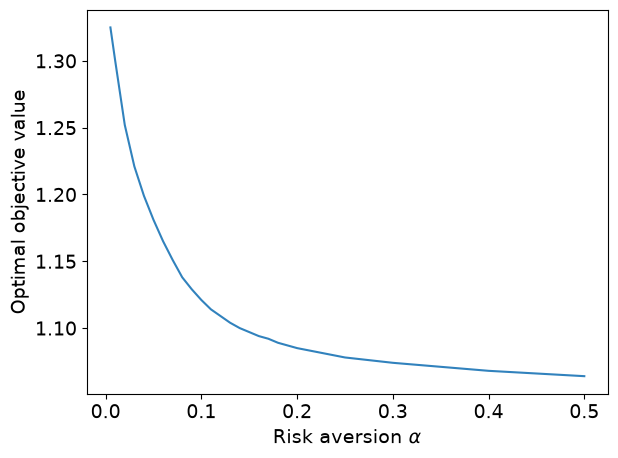

In [4]:
alpha_values = [
    0.005,
    0.01,
    0.02,
    0.03,
    0.04,
    0.05,
    0.06,
    0.07,
    0.08,
    0.09,
    0.1,
    0.11,
    0.12,
    0.13,
    0.14,
    0.15,
    0.16,
    0.17,
    0.18,
    0.19,
    0.20,
    0.25,
    0.3,
    0.4,
    0.5,
]
objective = []

plt.rcParams.update({"font.size": 14})
for alpha in alpha_values:
    model = markowitz_revisited(alpha, mu, Sigma)
    SOLVER.solve(model)
    objective.append(round(model.objective(), 3))

plt.plot(alpha_values, objective, color=plt.cm.tab20c(0))
plt.xlabel(r"Risk aversion $\alpha$")
plt.ylabel("Optimal objective value")
plt.tight_layout()
plt.show()